# Survival Analysis of a Breast-Cancer Trial (GBSG2)

Time-to-event analysis of the **German Breast Cancer Study Group 2 (GBSG2)**
trial — 686 node-positive breast-cancer patients followed for recurrence-free
survival, with hormonal-therapy assignment and standard prognostic factors.

This is the analysis workflow used to read out a clinical trial:

1. **Kaplan-Meier** estimation of the survival function
2. **Log-rank tests** comparing survival between groups (e.g. hormonal therapy)
3. **Cox proportional-hazards** regression for adjusted hazard ratios
4. Checking the **proportional-hazards assumption**

The same analysis is provided in **R** (`r/survival_analysis.R`, the `survival` /
`survminer` workflow used for peer-reviewed publication figures) and **SAS**
(`sas/survival_analysis.sas`, `PROC LIFETEST` / `PROC PHREG` as used for clinical
trial reporting). This notebook is the executed Python (`lifelines`) version.

*Data: GBSG2 trial, distributed publicly with the `lifelines` / R `TH.data` packages.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test

plt.rcParams["figure.dpi"] = 110
df = pd.read_csv("data/gbsg2.csv")
print(f"{len(df)} patients | {df['event'].sum()} events | {(df['event']==0).sum()} censored")
df.head()

686 patients | 299 events | 387 censored


,horTh,age,menostat,tsize,tgrade,pnodes,progrec,estrec,time_days,event
0,no,70,Post,21,II,3,48,66,1814,1
1,yes,56,Post,12,II,7,61,77,2018,1
2,yes,58,Post,35,II,9,52,271,712,1
3,yes,59,Post,17,II,4,60,29,1807,1
4,no,73,Post,35,II,1,26,65,772,1


## 1. Cohort overview

`time_days` is follow-up time; `event = 1` denotes recurrence/death, `0` denotes
a censored observation (patient event-free at last contact). `horTh` is the
hormonal-therapy assignment — the trial's primary comparison.

In [2]:
summary = pd.DataFrame({
    "n": [len(df)],
    "events": [int(df['event'].sum())],
    "censored": [int((df['event']==0).sum())],
    "median_followup_days": [df.loc[df['event']==0, 'time_days'].median()],
    "hormone_therapy_yes": [int((df['horTh']=='yes').sum())],
})
summary.T.rename(columns={0: "value"})

,value
n,686.0
events,299.0
censored,387.0
median_followup_days,1443.0
hormone_therapy_yes,246.0


## 2. Kaplan-Meier: overall recurrence-free survival

Median recurrence-free survival: 1807 days (4.9 years)


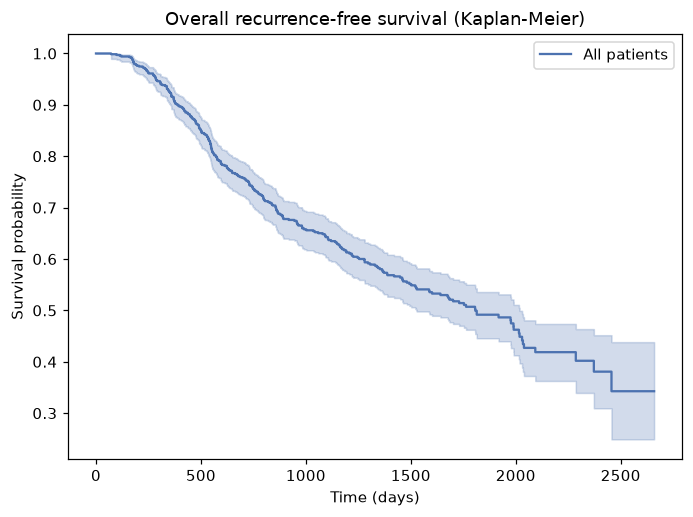

In [3]:
kmf = KaplanMeierFitter()
kmf.fit(df["time_days"], df["event"], label="All patients")

ax = kmf.plot_survival_function(ci_show=True, color="#4C72B0")
ax.set_title("Overall recurrence-free survival (Kaplan-Meier)")
ax.set_xlabel("Time (days)"); ax.set_ylabel("Survival probability")
median = kmf.median_survival_time_
print(f"Median recurrence-free survival: {median:.0f} days ({median/365.25:.1f} years)")
plt.tight_layout(); plt.savefig("figures/km_overall.png", bbox_inches="tight"); plt.show()

## 3. Does hormonal therapy improve survival?

We estimate separate KM curves for patients who did and did not receive hormonal
therapy, and test the difference with the **log-rank test**.

Log-rank test: chi2 = 8.56, p = 0.0034


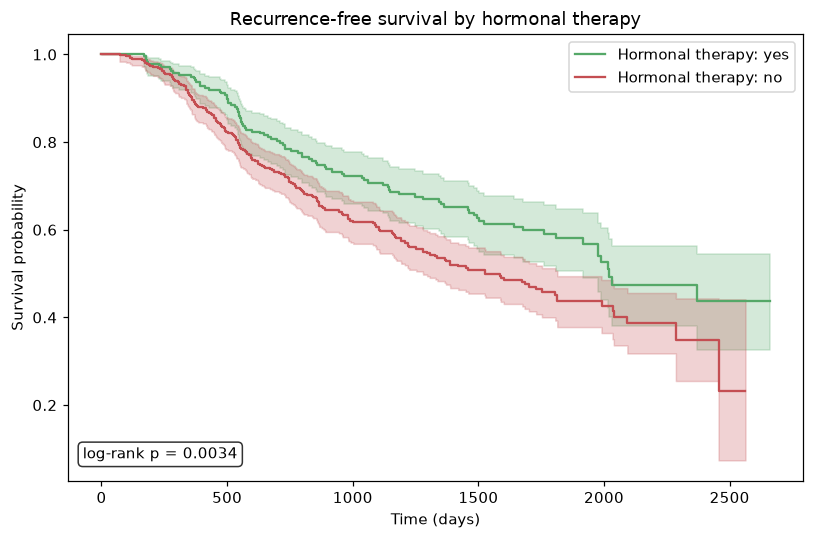

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for grp, color in [("yes", "#55A868"), ("no", "#C44E52")]:
    mask = df["horTh"] == grp
    KaplanMeierFitter().fit(df.loc[mask, "time_days"], df.loc[mask, "event"],
                            label=f"Hormonal therapy: {grp}").plot_survival_function(ax=ax, ci_show=True, color=color)
ax.set_title("Recurrence-free survival by hormonal therapy")
ax.set_xlabel("Time (days)"); ax.set_ylabel("Survival probability")

res = logrank_test(df.loc[df.horTh=="yes","time_days"], df.loc[df.horTh=="no","time_days"],
                   df.loc[df.horTh=="yes","event"], df.loc[df.horTh=="no","event"])
ax.text(0.02, 0.05, f"log-rank p = {res.p_value:.4f}", transform=ax.transAxes,
        bbox=dict(boxstyle="round", fc="white", alpha=.8))
print(f"Log-rank test: chi2 = {res.test_statistic:.2f}, p = {res.p_value:.4f}")
plt.tight_layout(); plt.savefig("figures/km_hormone.png", bbox_inches="tight"); plt.show()

## 4. Survival by tumor grade

Tumor grade (I / II / III) is a core prognostic factor; a multi-group log-rank
test checks whether survival differs across grades.

Multi-group log-rank: chi2 = 21.09, p = 0.0000


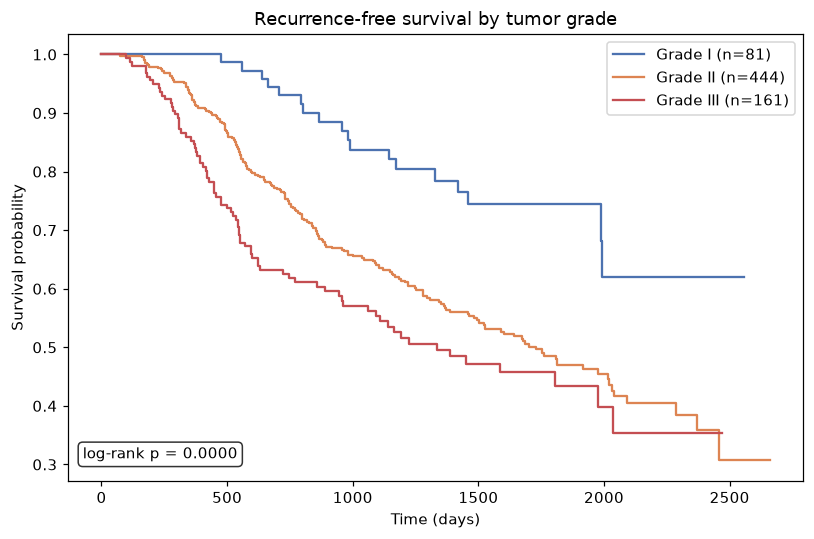

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 5))
palette = {"I": "#4C72B0", "II": "#DD8452", "III": "#C44E52"}
for grade in ["I", "II", "III"]:
    mask = df["tgrade"] == grade
    if mask.sum() == 0:
        continue
    KaplanMeierFitter().fit(df.loc[mask, "time_days"], df.loc[mask, "event"],
                            label=f"Grade {grade} (n={mask.sum()})").plot_survival_function(
                            ax=ax, ci_show=False, color=palette[grade])
ax.set_title("Recurrence-free survival by tumor grade")
ax.set_xlabel("Time (days)"); ax.set_ylabel("Survival probability")
mv = multivariate_logrank_test(df["time_days"], df["tgrade"], df["event"])
ax.text(0.02, 0.05, f"log-rank p = {mv.p_value:.4f}", transform=ax.transAxes,
        bbox=dict(boxstyle="round", fc="white", alpha=.8))
print(f"Multi-group log-rank: chi2 = {mv.test_statistic:.2f}, p = {mv.p_value:.4f}")
plt.tight_layout(); plt.savefig("figures/km_grade.png", bbox_inches="tight"); plt.show()

## 5. Cox proportional-hazards model

The log-rank test compares groups one factor at a time. A **Cox model** gives
*adjusted* hazard ratios (HR) for each covariate holding the others constant —
the standard multivariable read-out for a trial. We include hormonal therapy,
age, menopausal status, tumor size, number of positive nodes, and receptor
levels.

In [6]:
model_df = df.copy()
model_df["horTh"] = (model_df["horTh"] == "yes").astype(int)
model_df["menostat"] = (model_df["menostat"] == "Post").astype(int)
# ordinal tumor grade
model_df["tgrade"] = model_df["tgrade"].map({"I": 1, "II": 2, "III": 3})
model_df = model_df.drop(columns=[])  # keep all numeric predictors

cph = CoxPHFitter()
cph.fit(model_df, duration_col="time_days", event_col="event")
cph.print_summary(decimals=3)

<lifelines.CoxPHFitter: fitted with 686 total observations, 387 right-censored observations>
             duration col = 'time_days'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 686
number of events observed = 299
   partial log-likelihood = -1737.174
         time fit was run = 2026-07-23 15:47:38 UTC

---
            coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                   
horTh     -0.337     0.714     0.129          -0.590          -0.084               0.554               0.919
age       -0.009     0.991     0.009          -0.028           0.009               0.973               1.009
menostat   0.267     1.306     0.183          -0.092           0.627               0.912               1.871
tsize      0.008     1.008     0.004          -0.000           0.015               1.000               1.016
tgrade     0.280     1.324     0.106           0.072           0.488               1.075               1.629
pnodes     0.050     1.051     0.007           0.035           0.064               1.036               1.067
progrec   -0.002     0.998     0.001          -0.003          -0.001               0.997               0.999
estrec     0.000     1.000     0.000          -0.001           0.001               0.999               1.001

           cmp to      z       p  -log2(p)
covariate                                 
horTh       0.000 -2.615   0.009     6.807
age         0.000 -1.013   0.311     1.684
menostat    0.000  1.458   0.145     2.787
tsize       0.000  1.954   0.051     4.301
tgrade      0.000  2.643   0.008     6.926
pnodes      0.000  6.734 <0.0005    35.818
progrec     0.000 -3.887 <0.0005    13.265
estrec      0.000  0.374   0.708     0.497
---
Concordance = 0.688
Partial AIC = 3490.349
log-likelihood ratio test = 101.860 on 8 df
-log2(p) of ll-ratio test = 58.965

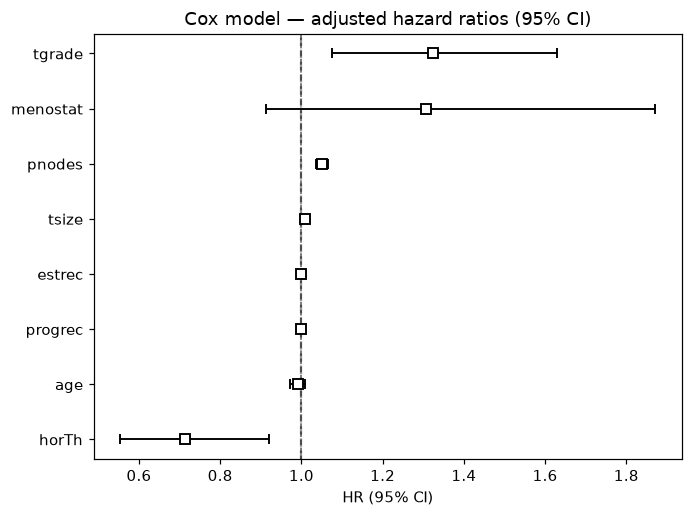

Model concordance (C-index): 0.688


In [7]:
ax = cph.plot(hazard_ratios=True)
ax.set_title("Cox model — adjusted hazard ratios (95% CI)")
ax.axvline(1.0, color="k", ls="--", alpha=.4)
plt.tight_layout(); plt.savefig("figures/cox_forest.png", bbox_inches="tight"); plt.show()

print(f"Model concordance (C-index): {cph.concordance_index_:.3f}")

## 6. Checking the proportional-hazards assumption

The Cox model assumes hazard ratios are constant over time. `lifelines` tests
this via scaled Schoenfeld residuals; a small p-value flags a covariate whose
effect changes over follow-up (which would call for a stratified or
time-varying model).

In [8]:
cph.check_assumptions(model_df, p_value_threshold=0.05, show_plots=False)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'tgrade' failed the non-proportional test: p-value is 0.0182.

   Advice: with so few unique values (only 3), you can include `strata=['tgrade', ...]` in the call
in `.fit`. See documentation in link [E] below.

---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Stratification



[]

## 7. Takeaways

- **Kaplan-Meier** curves and **log-rank tests** quantify recurrence-free
  survival overall and across prognostic groups (hormonal therapy, tumor grade).
- The **Cox model** yields adjusted hazard ratios: the number of positive lymph
  nodes and tumor grade carry the strongest adverse effect on recurrence, while
  hormonal therapy and higher progesterone receptor levels are protective —
  consistent with the established breast-cancer literature.
- The **proportional-hazards check** validates the modeling choice.

**Skills demonstrated:** survival / time-to-event analysis, Kaplan-Meier
estimation, log-rank testing, Cox proportional-hazards regression, hazard-ratio
interpretation, and model-assumption diagnostics — implemented in **Python,
R, and SAS** (see the `r/` and `sas/` folders).